# *Fermi*-LAT analysis with Fermipy v.1.4.1 🛰

This notebook is written to perform a standard analysis of *Fermi*-LAT data with *Fermipy* v1.4.1 and *Fermi ScienceTools* v2.2.0, by E. Bronzini. 

In case of any doubts always check the Cicerone webpage (https://fermi.gsfc.nasa.gov/ssc/data/analysis/documentation/Cicerone/) and the Fermipy documentation
(https://fermipy.readthedocs.io/en/latest/)

## Preliminary steps

Here, we summarize preliminary steps necessary to perform the analysis.

#### Import useful packages

Firstly, we import all the packages useful for the analysis.

In [1]:
%matplotlib inline
import os
import numpy as np
import astropy.io.fits as pyfits
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import csv
from astropy import units as u
from astropy.time import Time
from IPython.display import Image
from fermipy.gtanalysis import GTAnalysis
from fermipy.plotting import ROIPlotter, SEDPlotter
from glob import glob
from scipy.ndimage import gaussian_filter
import scipy.stats as stats
import subprocess

#### *Fermi*-LAT data

*Fermi*-LAT can be downloaded at the following site

https://fermi.gsfc.nasa.gov/cgi-bin/ssc/LAT/LATDataQuery.cgi


<img src="fermi_dataaccess.png">


For detailed description of input parameters please check the following link

https://fermi.gsfc.nasa.gov/ssc/LATDataQuery_help.html#LATdataType

    -) Region Of Interest (ROI): For the greatest accuracy possible in modeling a single source you should model the entire sky! This will usually not be feasible. Therefore, you will determine the size of the Source Region appropriate for your needs from experience and experimentation.

    -) Mission Elapsed Time (MET): number of seconds from January 1, 2001, in the UTC system. Useful date converters are
        
        https://tools.ssdc.asi.it/conversionTools#date
        
        https://heasarc.gsfc.nasa.gov/cgi-bin/Tools/xTime/xTime.pl


    -) LAT data type: the LAT instrument team makes cuts that classify the **events based on their photon probability** and the quality of their reconstruction. With "Photon" you select events that are probabably emitted by point-like sources.

#### Define directories

Here, we define our working directories. Photon list and the spacecraft files are in 'DATADIR', while the configuration file (see below) is located in 'WORKDIR'.

In [2]:
config_dir = '/home/bronzini/works/labx/3c111/3c111_fermi'
data_dir = '/blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_data'
work_dir = '/blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV'

### Make a configuration file

Make a configuration file ("config.yaml"). This should include every parameters of your analysis. A very simple example of a configuration file is the following.

<img src="config.png">

#### Remember to customize it to match your analysis goal!

Now, we make a file ("ft1.txt") that lists all the photon files of our analysis. The simplest  (and fastest) way to this is as follows:

In [3]:
if not os.path.exists(os.path.join(work_dir, 'ft1.txt')):
    command = f"ls -1 {data_dir}/*PH*.fits > {os.path.join(work_dir, 'ft1.txt')}"
    subprocess.run(command, shell=True, check=True)

## Start the analysis

Now we are ready for our analysis! 💪

### Optimize the basic model

Here the idea is to optimize the basic model from the latest catalog (4FGL-DR3 here). 

#### Setup the analysis
So, first we instantiate a GTAnalysis object with the path to the configuration file and run setup().

In [4]:
gta = GTAnalysis(os.path.join(config_dir,'3c111_config_140101_160101_300MeV1TeV.yaml'),logging={'verbosity': 3})
mpl.interactive(True)
gta.setup()

2026-11-05 16:25:51 INFO    GTAnalysis.__init__(): 
--------------------------------------------------------------------------------
fermipy version 1.4.1 
ScienceTools version 2.2.0
2026-11-05 16:25:53 INFO    GTAnalysis.setup(): Running setup.
2026-11-05 16:25:53 INFO    GTBinnedAnalysis.setup(): Running setup for component 00
2026-11-05 16:25:53 INFO    GTBinnedAnalysis._select_data(): Skipping data selection.
2026-11-05 16:25:53 INFO    GTBinnedAnalysis._create_ltcube(): Skipping LT Cube.
2026-11-05 16:25:54 INFO    GTBinnedAnalysis._create_expcube(): Skipping gtexpcube.
the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
Set MJD-OBS to 56658.000000 from DATE-OBS.
Set MJD-END to 57388.000000 from DATE-END'. [astropy.wcs.wcs]
2026-11-05 16:25:55 INFO    GTBinnedAnalysis._create_srcmaps(): Skipping gtsrcmaps.
2026-11-05 16:25:55 INFO    GTBinnedAnalysis.setup(): Finished setup for component 00
2026-11-05 16:25:55 INFO    GTBinnedAnalysis._create_binned_analysis(): Cre

Drm_Cache::update Measured counts < 0 4FGL J0325.2+4705 7 -2.27842e-11 3.424e-13
2.43689 0.111037 0.00268448 4.05354e-05 8.09257e-07 1.26302e-08 7.82738e-11 3.424e-13 


2026-11-05 16:26:01 INFO    GTAnalysis.setup(): Initializing source properties
2026-11-05 16:26:12 INFO    GTAnalysis.setup(): Finished setup.


In [5]:
gta.print_model()

2026-11-05 16:26:12 INFO    GTAnalysis.print_model(): 
sourcename            offset    norm  eflux     index        ts       npred free
--------------------------------------------------------------------------------
4FGL J0418.2+3807      0.097   0.717  4.08e-06   3.40       nan       472.8     
4FGL J0420.2+4012      2.204   0.672  3.43e-06   1.84       nan        61.8     
4FGL J0427.9+3632c     2.419   1.967  2.29e-06   4.71       nan       257.1     
4FGL J0409.7+4006c     2.670   1.639  2.16e-06   4.47       nan       221.7     
4FGL J0431.0+3529c     3.589   0.917  1.45e-06   4.48       nan       133.3     
4FGL J0400.7+3920      3.682   2.431  2.28e-06   2.12       nan        93.8     
4FGL J0418.4+3414      3.788   1.504  1.15e-06   2.47       nan        88.8     
4FGL J0423.9+4150      3.954   0.740  1.81e-05   1.89       nan       581.5     
4FGL J0359.3+3626      4.105   1.112  1.28e-06   4.20       nan       120.5     
4FGL J0410.9+4216      4.480   2.576  3.51e-06   2.21 

2026-11-05 16:26:12 INFO    GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/pre_opt_00.xml...
2026-11-05 16:26:12 INFO    GTAnalysis.write_fits(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/pre_opt.fits...
2026-11-05 16:26:15 INFO    GTBinnedAnalysis.write_model_map(): Generating model map for component 00.
2026-11-05 16:26:16 INFO    GTAnalysis.write_roi(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/pre_opt.npy...


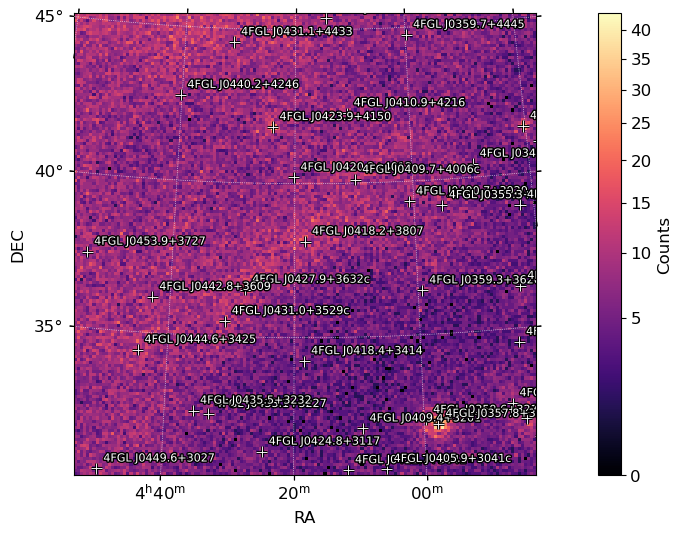

In [6]:
gta.write_roi(os.path.join(work_dir,'pre_opt'),make_plots=True,save_model_map=True)
plt.show()

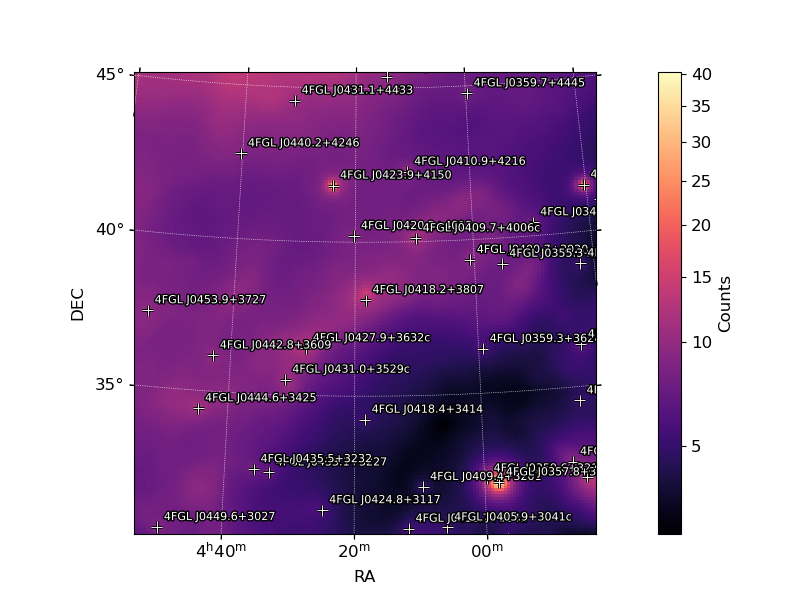

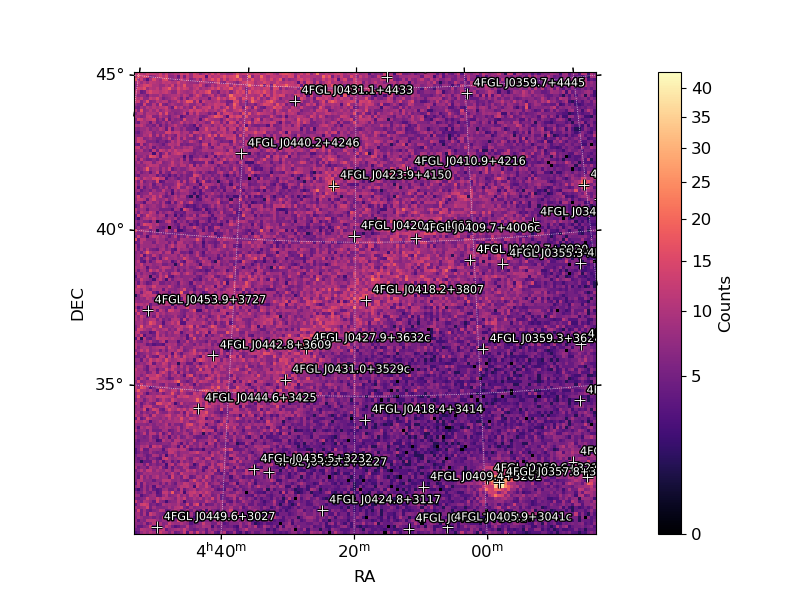

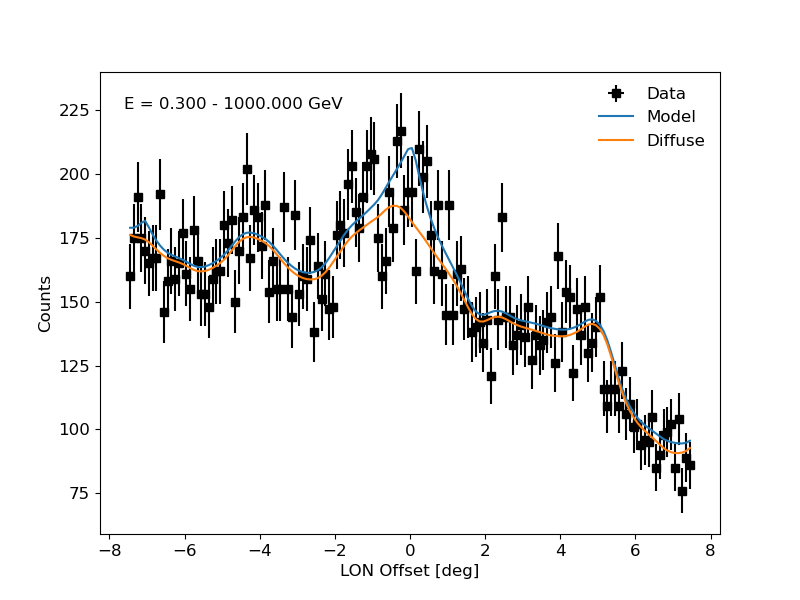

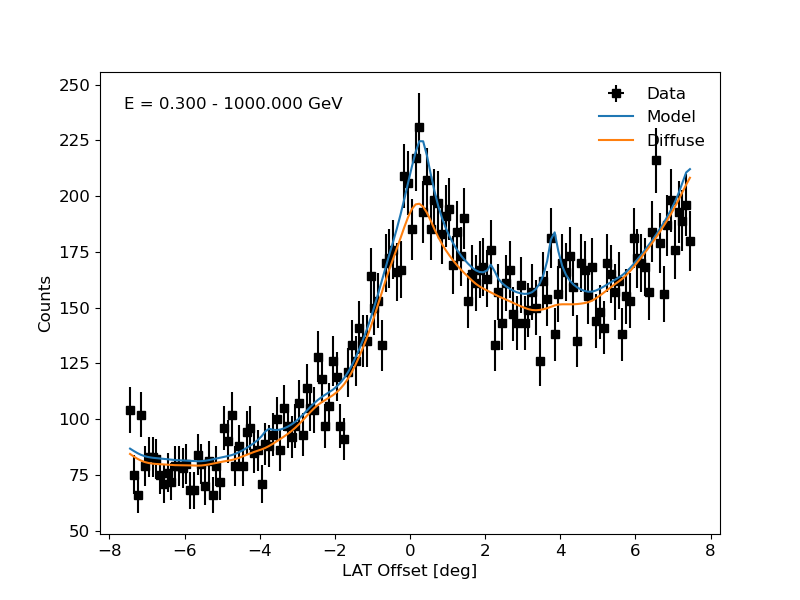

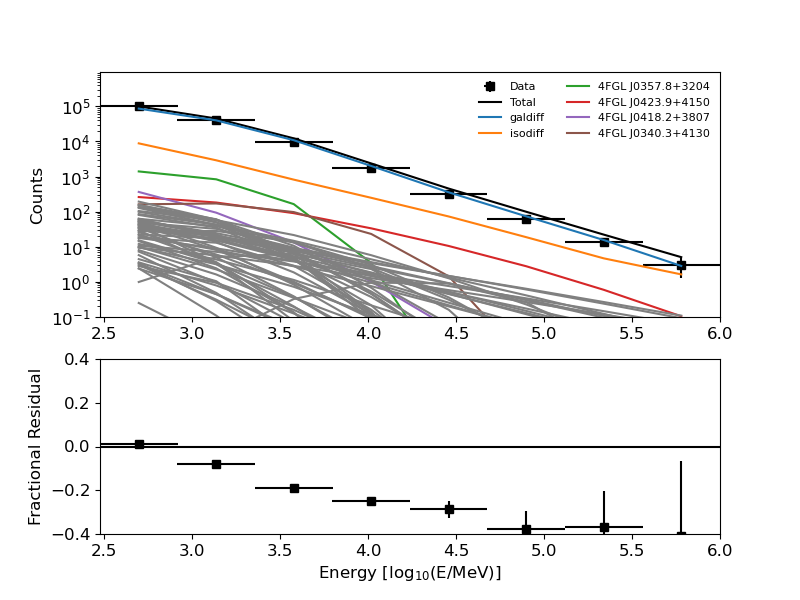

In [7]:
pngs = glob(os.path.join(work_dir,'*pre_opt*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

As you can see, sources are listed based on their distance from the center of the ROI. Typically, you center the ROI on the source you are interested in. For this reason, we define the variable **srcname** as follows 

In [8]:
gta.print_roi()
srcname = gta.roi.sources[0].name

2026-11-05 16:26:22 INFO    GTAnalysis.print_roi(): 
name                SpatialModel   SpectrumType     offset        ts       npred
--------------------------------------------------------------------------------
4FGL J0418.2+3807   PointSource    LogParabola       0.097       nan       472.8
4FGL J0420.2+4012   PointSource    PowerLaw          2.204       nan        61.8
4FGL J0427.9+3632c  PointSource    LogParabola       2.419       nan       257.1
4FGL J0409.7+4006c  PointSource    LogParabola       2.670       nan       221.7
4FGL J0431.0+3529c  PointSource    LogParabola       3.589       nan       133.3
4FGL J0400.7+3920   PointSource    PowerLaw          3.682       nan        93.8
4FGL J0418.4+3414   PointSource    PowerLaw          3.788       nan        88.8
4FGL J0423.9+4150   PointSource    LogParabola       3.954       nan       581.5
4FGL J0359.3+3626   PointSource    LogParabola       4.105       nan       120.5
4FGL J0410.9+4216   PointSource    LogParabola       4.4

With *gta.setup()* function, we generated all files needed for the analysis, including the count cube (*ccube.fits*). You can inspect it with ds9 (or here in python). In the following, we give a very simple way to do that. In particular, summing over all energies, here we show the count map.

Filename: /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/ccube.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      28   (150, 150, 8)   float32   
  1  EBOUNDS       1 BinTableHDU     22   8R x 4C   [K, D, D, D]   


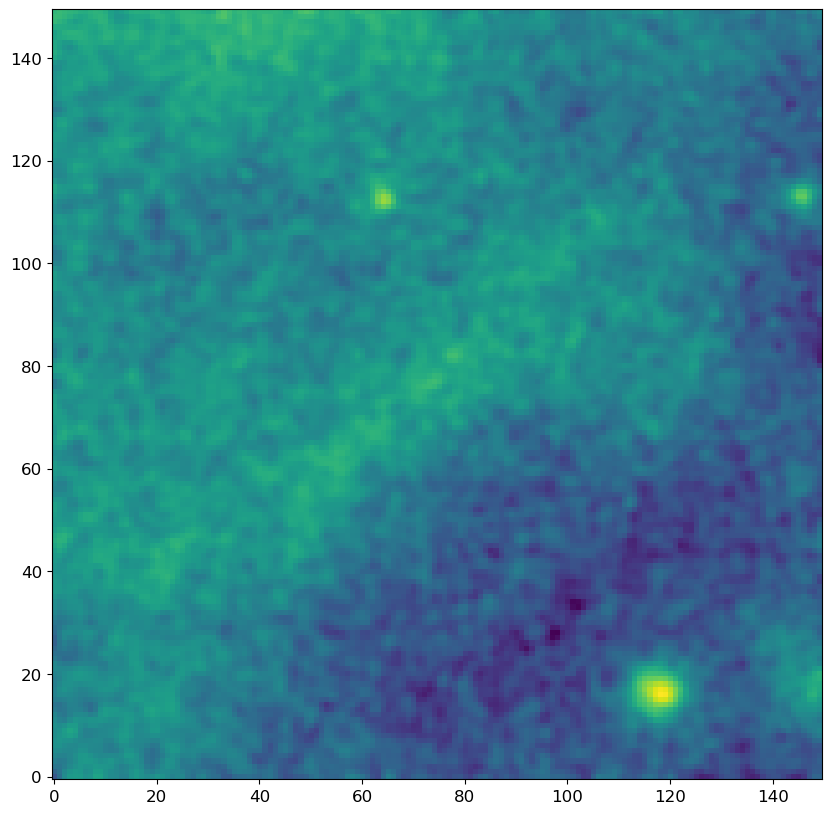

In [9]:
h = pyfits.open(os.path.join(work_dir,'ccube.fits'))
h.info()
counts = h[0].data
counts.shape
plt.figure(figsize=(10,10))
filtered_arr=gaussian_filter(np.sum(counts,axis=0), 1)
plt.imshow(filtered_arr,interpolation='nearest',origin='lower',norm='log',cmap='viridis')
plt.show()

The setup() method performs the data preparation and response calculations needed for the analysis (selecting the data, creating counts and exposure maps, etc.). Depending on the data selection and binning of the analysis this will often be the slowest step in the analysis sequence. The output of setup() is cached in the analysis working directory so subsequent calls to setup() will run much faster.

#### Optimize the model
Before running any other analysis methods it is recommended to first run optimize(). This will loop over all model components in the ROI and fit their normalization and spectral shape parameters. This method also computes the TS of all sources which can be useful for identifying weak sources that could be fixed or removed from the model. We can check the results of the optimization step by calling print_roi():

This will loop over all model components in the ROI and fit their normalization and spectral shape parameters. This method also computes the TS of all sources which can be useful for identifying weak sources that could be fixed or removed from the model. We can check the results of the optimization step by calling print_roi():

In [10]:
opt = gta.optimize()
gta.print_model()
gta.write_roi(os.path.join(work_dir,'opt_model'),make_plots=True,save_model_map=True)

2026-11-05 16:26:22 INFO    GTAnalysis.optimize(): Starting


Joint fit  ['galdiff', 'isodiff']


/home/bronzini/.conda/envs/my_fermipy_v1.4.1/lib/python3.9/site-packages/fermipy/utils.py:793: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y, k=2,


Fitting shape galdiff TS:  13027.228
Fitting shape 4FGL J0357.8+3204 TS:   2609.210
Fitting shape 4FGL J0340.3+4130 TS:    438.610
Fitting shape 4FGL J0423.9+4150 TS:    429.564
Fitting shape isodiff TS:    317.749
Fitting shape 4FGL J0418.2+3807 TS:     69.828
Fitting shape 4FGL J0410.9+4216 TS:     48.955
Fitting shape 4FGL J0502.5+3438 TS:     41.072
Fitting shape 4FGL J0427.9+3632c TS:     40.442
Fitting shape 4FGL J0444.6+3425 TS:     39.674
Fitting shape 4FGL J0409.7+4006c TS:     25.058


2026-11-05 16:27:18 INFO    GTAnalysis.optimize(): Finished
2026-11-05 16:27:18 INFO    GTAnalysis.optimize(): LogLike: 15108.745042 Delta-LogLike: 528.197447
2026-11-05 16:27:18 INFO    GTAnalysis.optimize(): Execution time: 56.00 s
2026-11-05 16:27:18 INFO    GTAnalysis.print_model(): 
sourcename            offset    norm  eflux     index        ts       npred free
--------------------------------------------------------------------------------
4FGL J0418.2+3807      0.097   0.829  4.92e-06   3.07     59.25       659.3     
4FGL J0420.2+4012      2.204   0.000  7.13e-11   1.84     -0.00         0.0     
4FGL J0427.9+3632c     2.419   2.827  3.75e-06   3.66     31.97       425.1     
4FGL J0409.7+4006c     2.670   1.547  3.47e-06   2.78     28.90       425.3     
4FGL J0431.0+3529c     3.589   1.549  2.45e-06   4.48     14.56       225.1     
4FGL J0400.7+3920      3.682   1.903  1.79e-06   2.12      4.90        73.4     
4FGL J0418.4+3414      3.788   0.439  3.36e-07   2.47      0.33

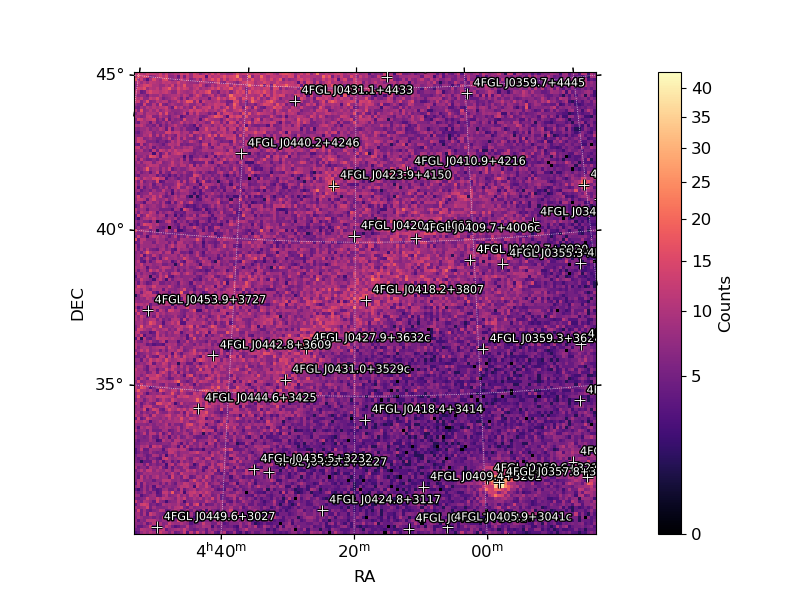

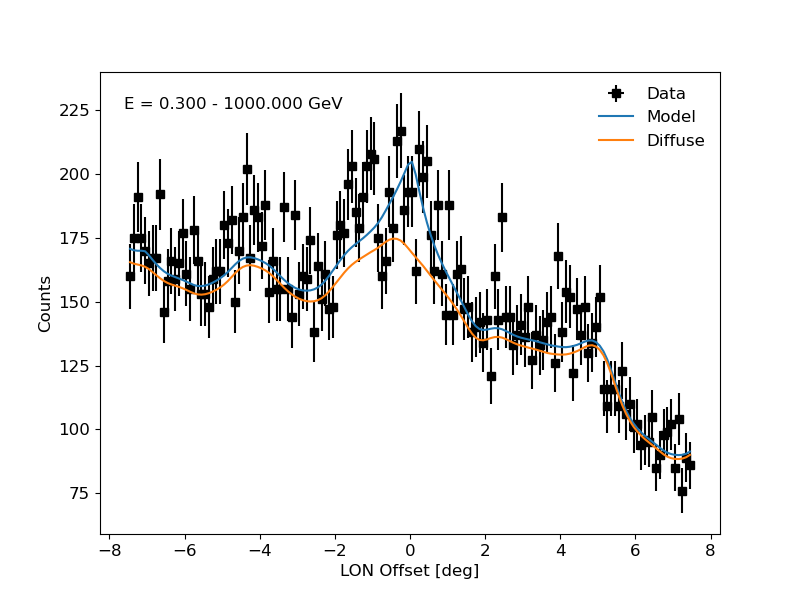

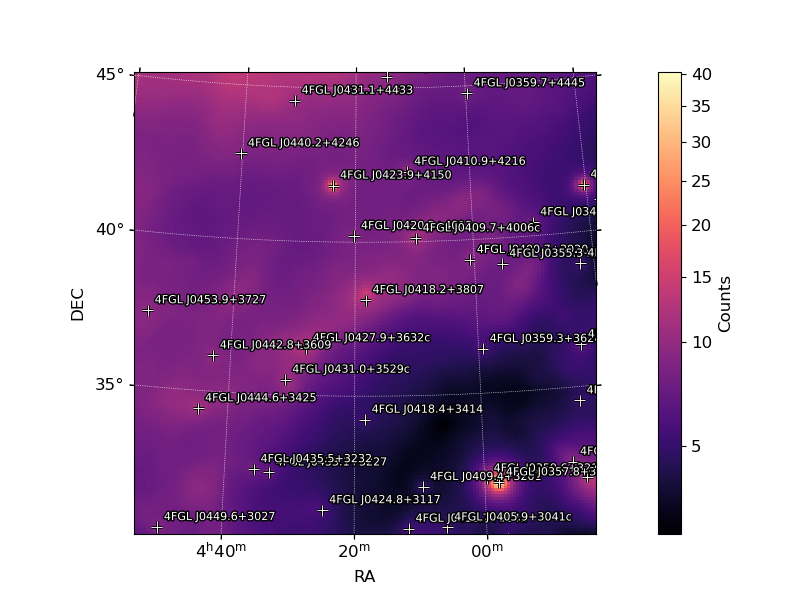

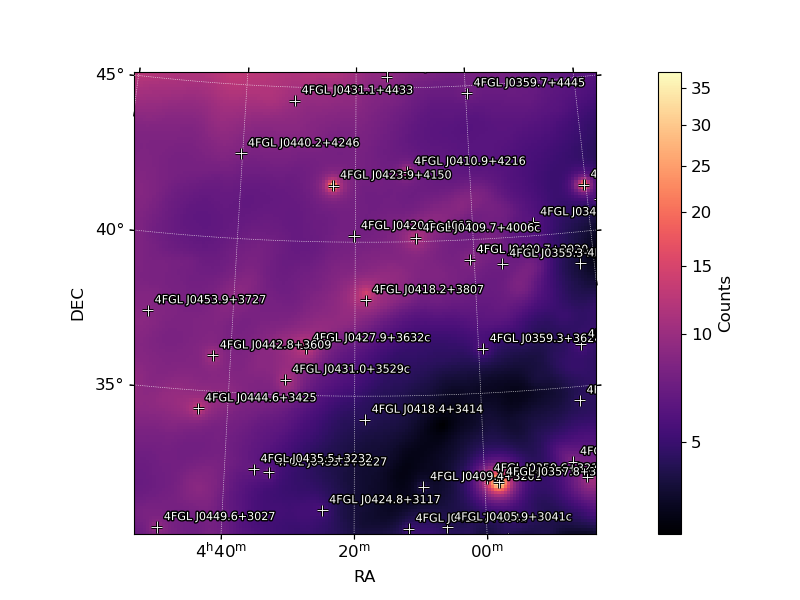

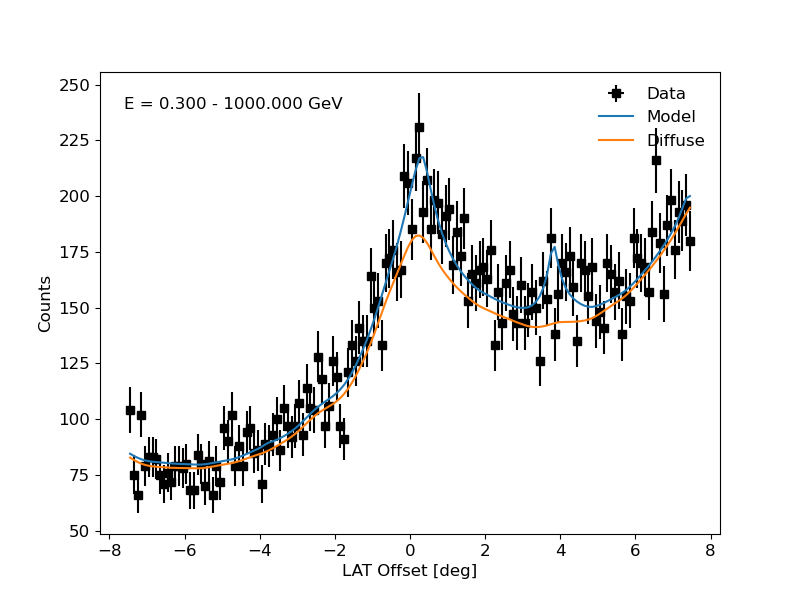

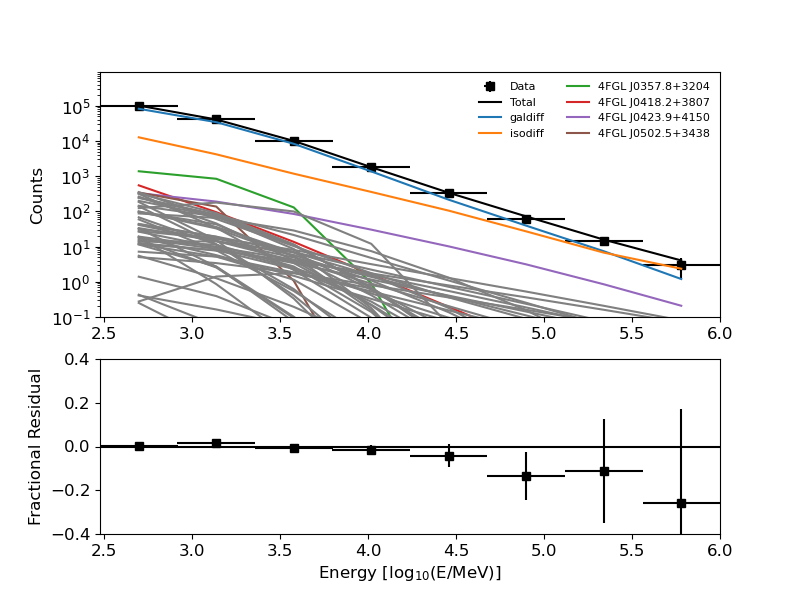

In [11]:
pngs = glob(os.path.join(work_dir,'*opt_model*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

In [12]:
gta.print_model()

2026-11-05 16:27:25 INFO    GTAnalysis.print_model(): 
sourcename            offset    norm  eflux     index        ts       npred free
--------------------------------------------------------------------------------
4FGL J0418.2+3807      0.097   0.829  4.92e-06   3.07     59.25       659.3     
4FGL J0420.2+4012      2.204   0.000  7.13e-11   1.84     -0.00         0.0     
4FGL J0427.9+3632c     2.419   2.827  3.75e-06   3.66     31.97       425.1     
4FGL J0409.7+4006c     2.670   1.547  3.47e-06   2.78     28.90       425.3     
4FGL J0431.0+3529c     3.589   1.549  2.45e-06   4.48     14.56       225.1     
4FGL J0400.7+3920      3.682   1.903  1.79e-06   2.12      4.90        73.4     
4FGL J0418.4+3414      3.788   0.439  3.36e-07   2.47      0.33        25.9     
4FGL J0423.9+4150      3.954   0.706  1.95e-05   1.96    482.56       648.2     
4FGL J0359.3+3626      4.105   1.349  1.55e-06   4.20     10.97       146.2     
4FGL J0410.9+4216      4.480   3.307  3.87e-06   2.16 

#### Freeing sources

By default all models parameters are initially fixed. The free_source() and free_sources() methods can be use to free or fix parameters of the model. In the following example we free the normalization of catalog sources within 3 deg of the ROI center and free the galactic and isotropic components by name.

In [13]:
gta.free_sources(free=False)

gta.free_source('isodiff')
gta.free_source('galdiff')
gta.free_sources(distance=5.0,pars='norm')
gta.free_sources(minmax_ts=[None,4],free=False)
gta.free_sources(minmax_ts=[100,None],pars='norm')
gta.free_sources(distance=3.0)


gta.print_model()

2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for isodiff               : ['Normalization']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for galdiff               : ['Prefactor', 'Index']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0418.2+3807     : ['norm']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0420.2+4012     : ['Prefactor']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0427.9+3632c    : ['norm']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0409.7+4006c    : ['norm']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0431.0+3529c    : ['norm']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0400.7+3920     : ['Prefactor']
2026-11-05 16:27:25 INFO    GTAnalysis.free_source(): Freeing parameters for 4FGL J0418

In [14]:
free = gta.fit()
gta.print_model()
gta.write_roi(os.path.join(work_dir, 'free_model'),make_plots=True,save_model_map=True)

2026-11-05 16:27:25 INFO    GTAnalysis.fit(): Starting fit.
/home/bronzini/.conda/envs/my_fermipy_v1.4.1/lib/python3.9/site-packages/fermipy/utils.py:793: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y, k=2,
2026-11-05 16:27:47 INFO    GTAnalysis.fit(): Fit returned successfully. Quality:   3 Status:   0
2026-11-05 16:27:47 INFO    GTAnalysis.fit(): LogLike:    15117.860 DeltaLogLike:        9.115 
2026-11-05 16:27:47 INFO    GTAnalysis.print_model(): 
sourcename            offset    norm  eflux     index        ts       npred free
--------------------------------------------------------------------------------
4FGL J0418.2+3807      0.097   0.746  4.48e-06   3.04     45.67       584.6    *
4FGL J0420.2+

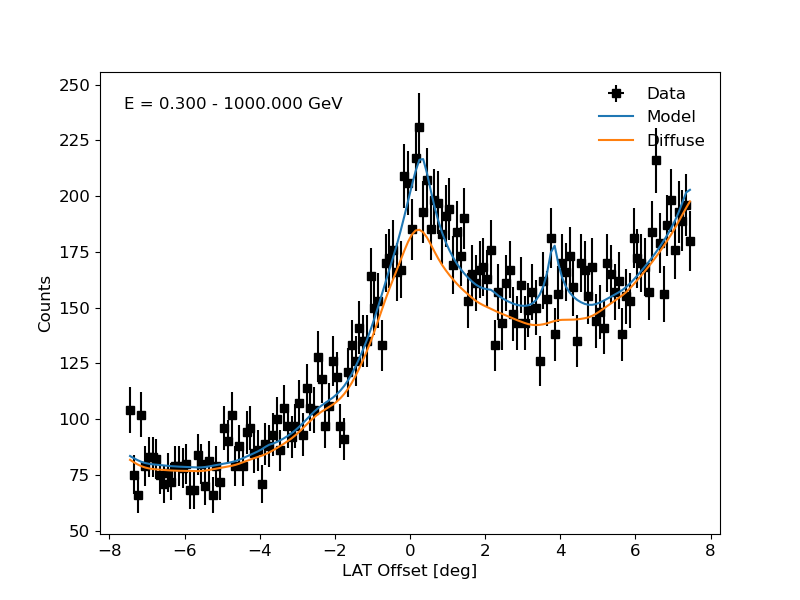

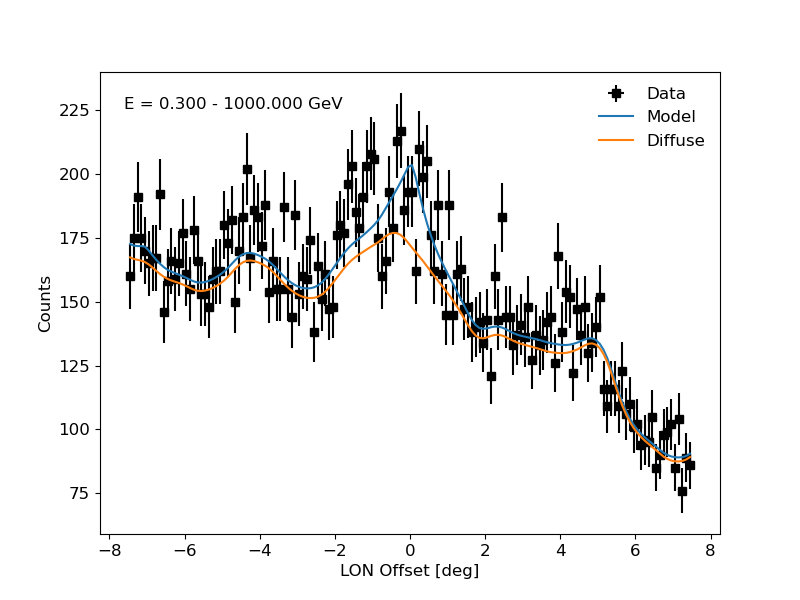

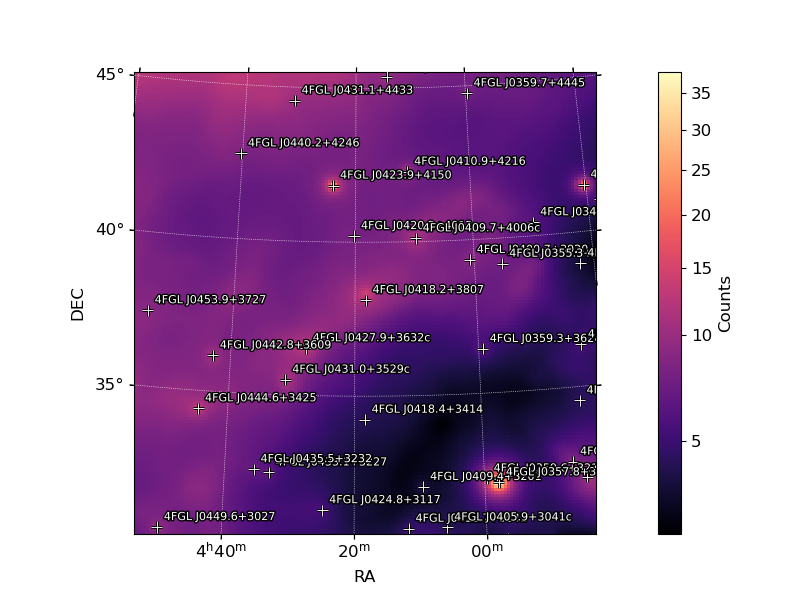

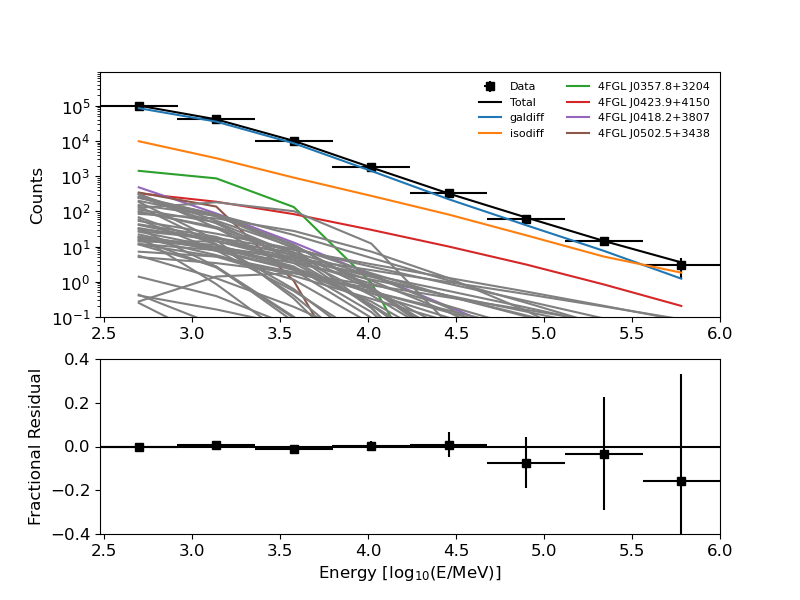

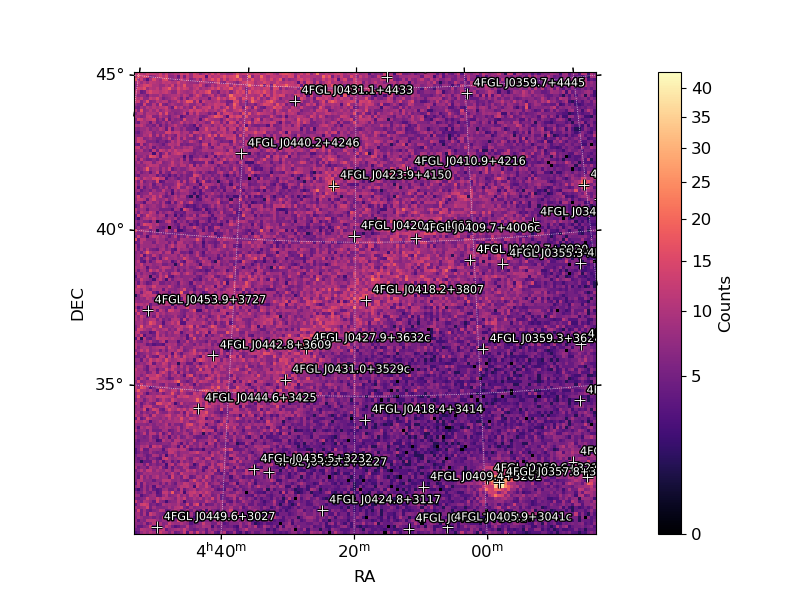

In [15]:
pngs = glob(os.path.join(work_dir,'*free_model*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

#### Fit

After freeing parameters of the model we can execute a likelihood fit by calling fit(). This will maximize the likelihood with respect to the model parameters that are currently free. We can immediately check the fit quality as follows (Fit Quality:  3 => very good fit). After the fitting is complete we can write the current state of the model with write_roi.

In [16]:
print('Fit Quality: ',free['fit_quality'])
print(gta.roi)

Fit Quality:  3
name                SpatialModel   SpectrumType     offset        ts       npred
--------------------------------------------------------------------------------
4FGL J0418.2+3807   PointSource    LogParabola       0.097     45.67       584.6
4FGL J0420.2+4012   PointSource    PowerLaw          2.204      0.52        32.5
4FGL J0427.9+3632c  PointSource    LogParabola       2.419     23.36       353.6
4FGL J0409.7+4006c  PointSource    LogParabola       2.670     21.93       368.8
4FGL J0431.0+3529c  PointSource    LogParabola       3.589     16.39       235.5
4FGL J0400.7+3920   PointSource    PowerLaw          3.682      8.18        89.3
4FGL J0418.4+3414   PointSource    PowerLaw          3.788      0.33        25.9
4FGL J0423.9+4150   PointSource    LogParabola       3.954    477.88       641.2
4FGL J0359.3+3626   PointSource    LogParabola       4.105     14.80       168.4
4FGL J0410.9+4216   PointSource    LogParabola       4.480     59.22       184.4
4FGL J0355.3

### Improve the model

Now, we improve the model from the latest catalog.

#### Delete non-detected sources

In [17]:
deleted_sources = gta.delete_sources(minmax_ts=[-1,3])

2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0420.2+4012
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0418.4+3414
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0349.6+4026
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0409.4+3201
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0440.2+4246
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0431.1+4433
2026-11-05 16:27:54 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0453.9+3727
2026-11-05 16:27:55 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0342.2+3858
2026-11-05 16:27:55 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0411.7+3041
2026-11-05 16:27:55 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0344.4+3432
2026-11-05 16:27:55 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0405.9+3041c
2026-11-0

#### Find new sources

Let's see if there are any new sources not listed in the catalog.

In [18]:
model = {'Index' : 2.0, 'SpatialModel' : 'PointSource'}
srcs = gta.find_sources(model=model, sqrt_ts_threshold=5.0,
                        min_separation=0.5)

2026-11-05 16:27:56 INFO    GTAnalysis.find_sources(): Starting.
2026-11-05 16:27:56 INFO    GTAnalysis.tsmap(): Generating TS map
2026-11-05 16:27:58 INFO    GTAnalysis._make_tsmap_fast(): Fitting test source.
2026-11-05 16:28:27 INFO    GTAnalysis.tsmap(): Finished TS map
2026-11-05 16:28:27 WARNING GTAnalysis.tsmap(): Saving TS maps in .npy files is disabled b/c of incompatibilities in python3, remove the maps from the /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/sourcefind_00_pointsource_powerlaw_2.00_tsmap.npy
2026-11-05 16:28:27 INFO    GTAnalysis.tsmap(): Execution time: 30.83 s
2026-11-05 16:28:27 INFO    GTAnalysis.find_sources(): Found 0 sources in iteration 0.
2026-11-05 16:28:27 INFO    GTAnalysis.find_sources(): Done.
2026-11-05 16:28:27 INFO    GTAnalysis.find_sources(): Execution time: 30.84 s


#### Fit

Now, we fit the model again to take into account the new sources, if any. After the fitting is complete we write the current state of the model with write_roi.

In [19]:
new_fit = gta.fit()
gta.write_roi(os.path.join(work_dir,'model_news'),make_plots=True,save_model_map=True)

2026-11-05 16:28:27 INFO    GTAnalysis.fit(): Starting fit.
/home/bronzini/.conda/envs/my_fermipy_v1.4.1/lib/python3.9/site-packages/fermipy/utils.py:793: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y, k=2,
2026-11-05 16:28:42 INFO    GTAnalysis.fit(): Fit returned successfully. Quality:   3 Status:   0
2026-11-05 16:28:42 INFO    GTAnalysis.fit(): LogLike:    15110.455 DeltaLogLike:        1.906 
2026-11-05 16:28:42 INFO    GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/model_news_00.xml...
2026-11-05 16:28:42 INFO    GTAnalysis.write_fits(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fe

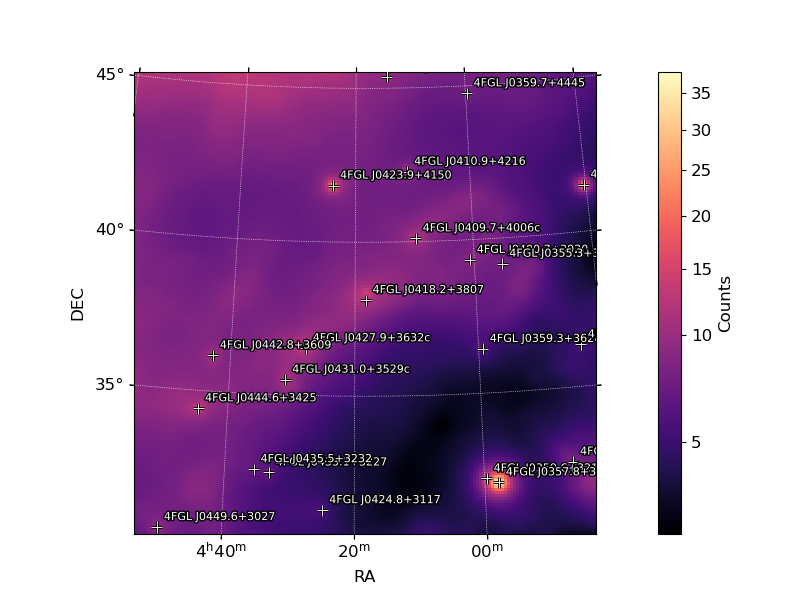

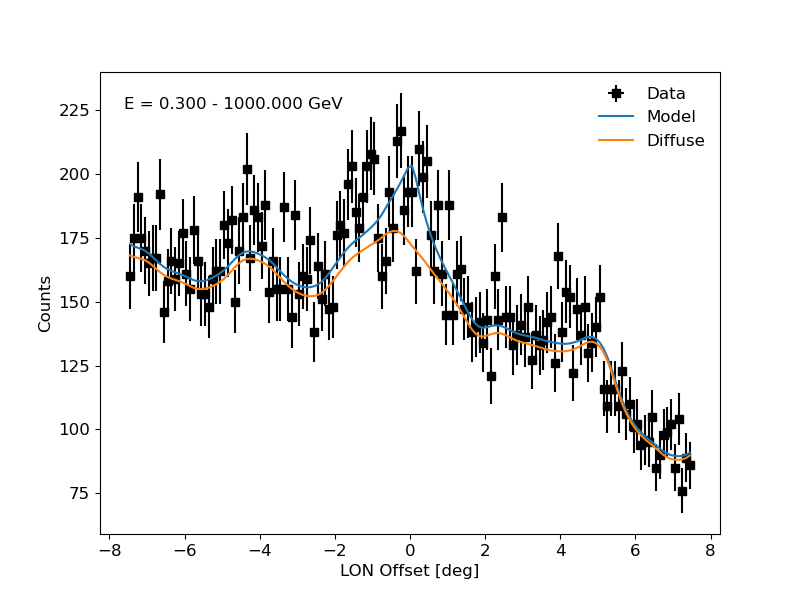

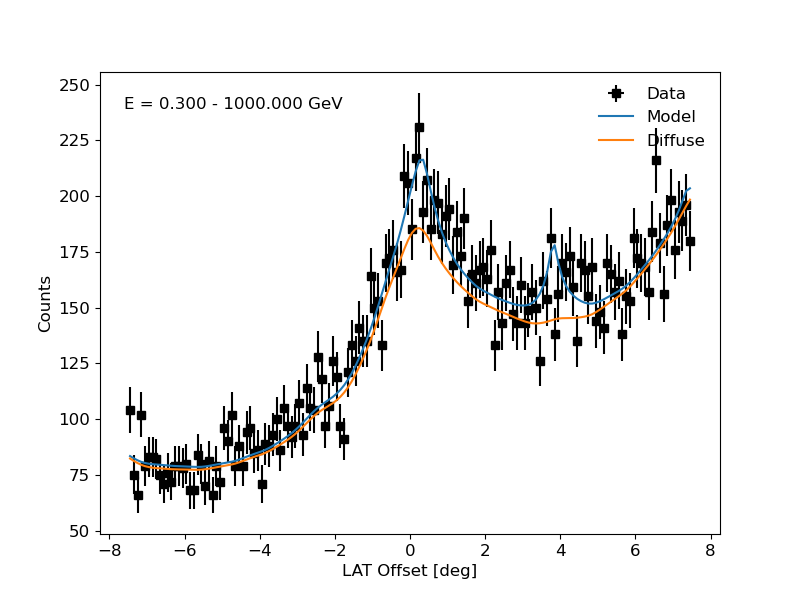

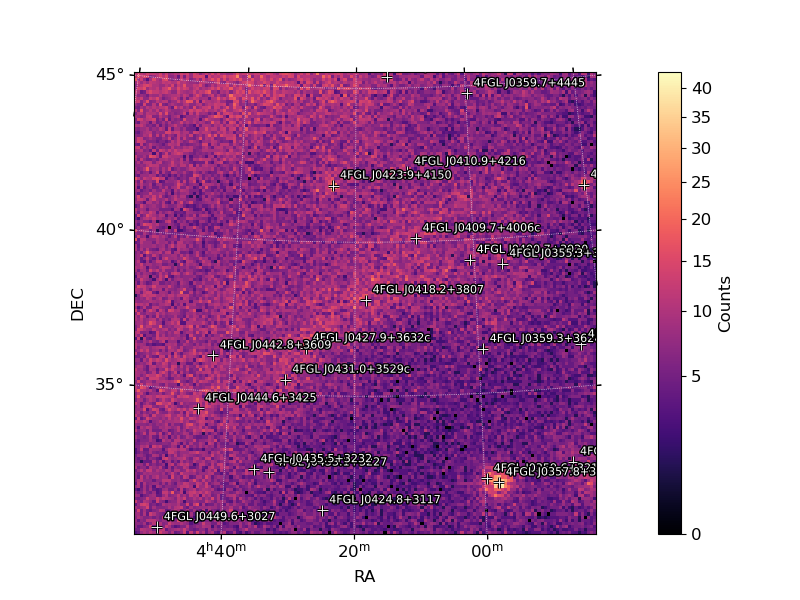

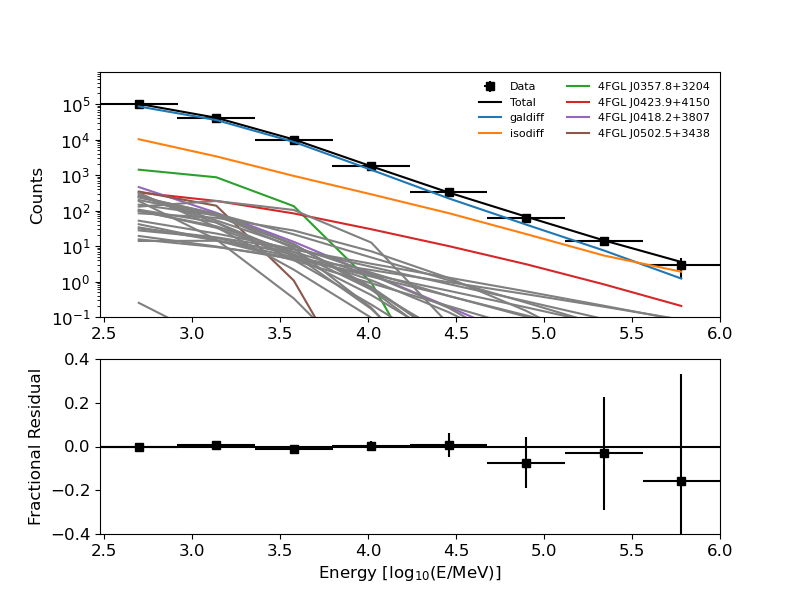

In [20]:
pngs = glob(os.path.join(work_dir,'*model_news*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

In [21]:
gta.print_model()

2026-11-05 16:28:47 INFO    GTAnalysis.print_model(): 
sourcename            offset    norm  eflux     index        ts       npred free
--------------------------------------------------------------------------------
4FGL J0418.2+3807      0.097   0.726  4.37e-06   3.04     43.01       560.0    *
4FGL J0427.9+3632c     2.419   2.483  3.13e-06   3.70     21.52       324.8    *
4FGL J0409.7+4006c     2.670   1.327  3.06e-06   2.71     20.02       344.8    *
4FGL J0431.0+3529c     3.589   1.574  2.49e-06   4.48     15.49       228.6    *
4FGL J0400.7+3920      3.682   2.233   2.1e-06   2.12      7.71        86.2    *
4FGL J0423.9+4150      3.954   0.693  1.91e-05   1.96    474.30       636.3    *
4FGL J0359.3+3626      4.105   1.455  1.67e-06   4.20     13.13       157.8    *
4FGL J0410.9+4216      4.480   3.160   3.7e-06   2.16     58.04       181.6    *
4FGL J0355.3+3909      4.639   1.427  2.35e-06   1.78     14.82        33.2    *
4FGL J0442.8+3609      5.225   1.380  3.19e-06   3.57 

#### Source localization
Let's check the peak position of $\gamma$-ray source.

In [22]:
loc = gta.localize(srcname ,make_plots=True)

2026-11-05 16:28:47 INFO    GTAnalysis.localize(): Running localization for 4FGL J0418.2+3807
2026-11-05 16:28:59 INFO    GTAnalysis._localize(): Localization succeeded.
2026-11-05 16:28:59 INFO    GTAnalysis._localize(): Updating source 4FGL J0418.2+3807 to localized position.
2026-11-05 16:28:59 INFO    GTAnalysis.delete_source(): Deleting source 4FGL J0418.2+3807
2026-11-05 16:28:59 INFO    GTAnalysis.add_source(): Adding source 4FGL J0418.2+3807
2026-11-05 16:29:00 INFO    GTAnalysis._localize(): Localization completed with new position:
(  ra, dec) = (   64.5280 +/-   0.1401,   38.3491 +/-   0.1382)
(glon,glat) = (  161.4108 +/-   0.1833,   -8.6253 +/-   0.0718)
offset =   0.2289 r68 =   0.1739 r95 =   0.2806 r99 =   0.3480
2026-11-05 16:29:00 INFO    GTAnalysis._localize(): LogLike:    15110.445 DeltaLogLike:       -0.011
2026-11-05 16:29:00 INFO    GTAnalysis.localize(): Finished localization.
2026-11-05 16:29:03 WARNING GTAnalysis.localize(): Saving TS maps in .npy files is dis

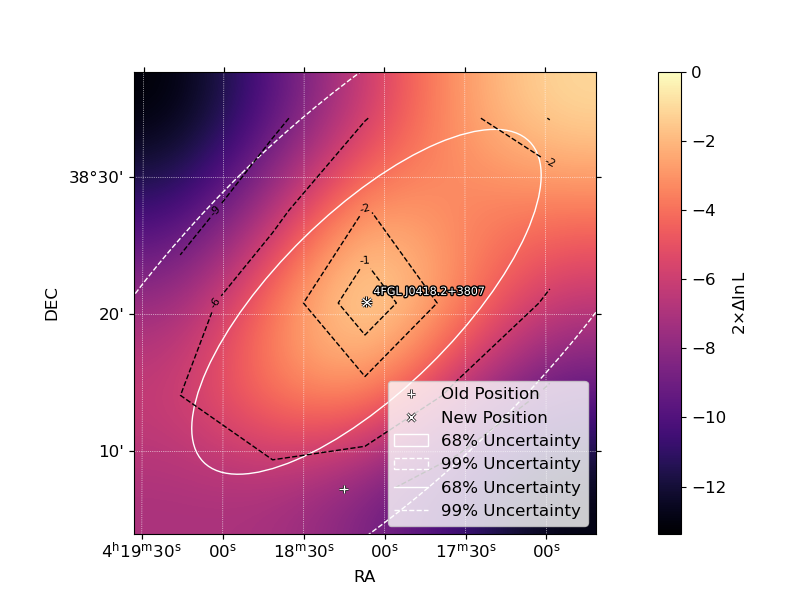

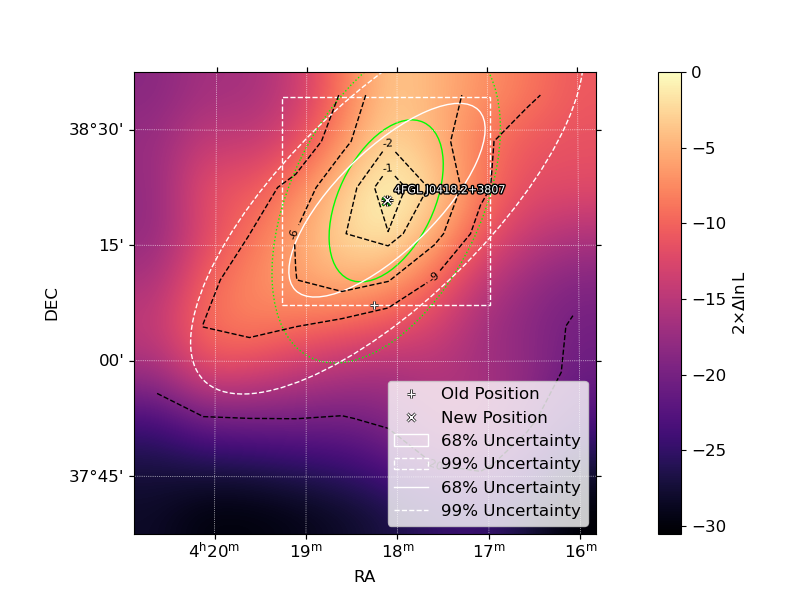

In [23]:
pngs = glob(os.path.join(work_dir,'*localize*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

In [24]:
loc_fit = gta.fit()
gta.write_roi(os.path.join(work_dir,'model_loc'),make_plots=True,save_model_map=True)

2026-11-05 16:29:03 INFO    GTAnalysis.fit(): Starting fit.
/home/bronzini/.conda/envs/my_fermipy_v1.4.1/lib/python3.9/site-packages/fermipy/utils.py:793: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y, k=2,
2026-11-05 16:29:18 INFO    GTAnalysis.fit(): Fit returned successfully. Quality:   3 Status:   0
2026-11-05 16:29:18 INFO    GTAnalysis.fit(): LogLike:    15110.445 DeltaLogLike:        0.000 
2026-11-05 16:29:18 INFO    GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/model_loc_00.xml...
2026-11-05 16:29:18 INFO    GTAnalysis.write_fits(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fer

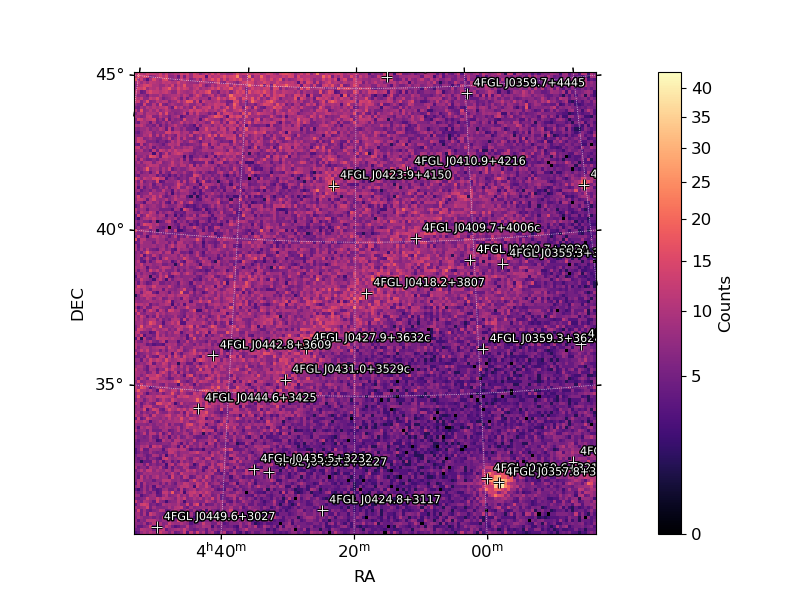

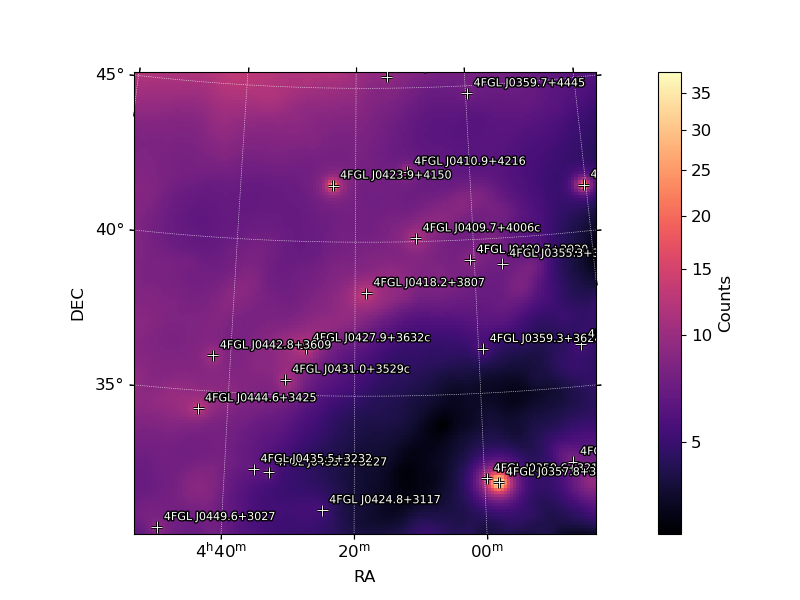

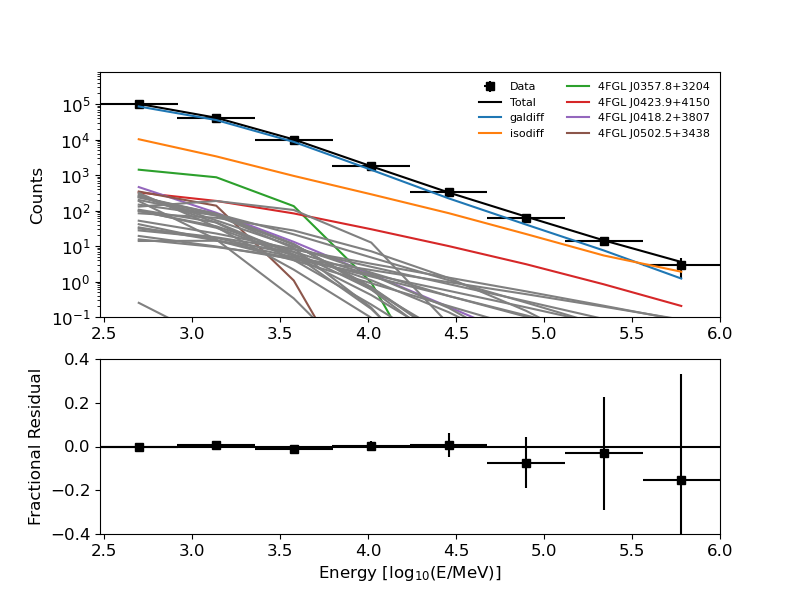

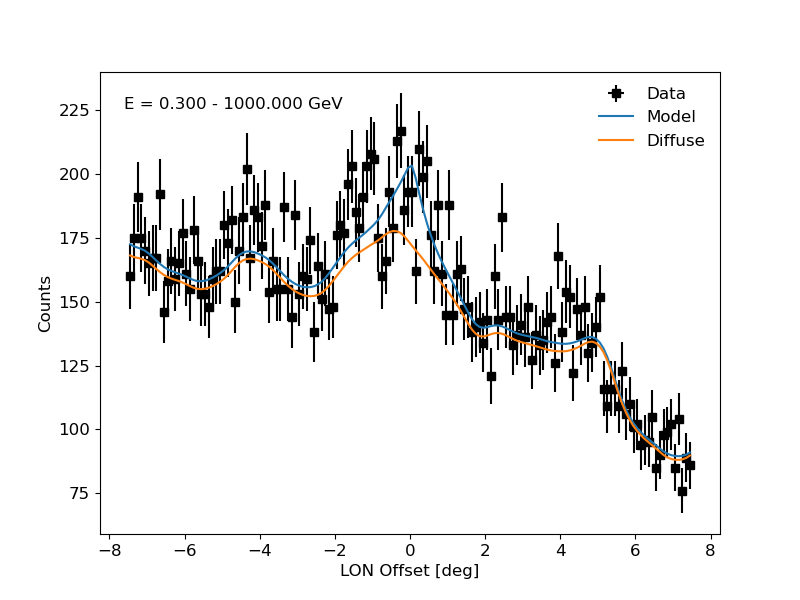

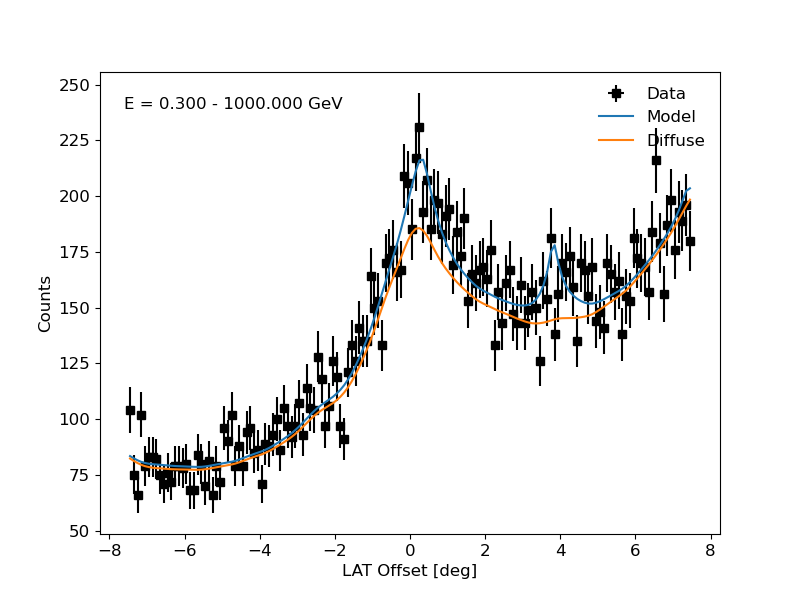

In [25]:
pngs = glob(os.path.join(work_dir,'*model_loc*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

### TS map

In [26]:
model = {'Index' : 2.0, 'SpatialModel' : 'PointSource'}
tsmap = gta.tsmap(multithread=True,make_plots=True,write_fits=True,write_npy=True)

2026-11-05 16:29:24 INFO    GTAnalysis.tsmap(): Generating TS map
2026-11-05 16:29:25 INFO    GTAnalysis._make_tsmap_fast(): Fitting test source.
2026-11-05 16:29:45 INFO    GTAnalysis.tsmap(): Finished TS map
2026-11-05 16:29:45 WARNING GTAnalysis.tsmap(): Saving TS maps in .npy files is disabled b/c of incompatibilities in python3, remove the maps from the /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/pointsource_powerlaw_2.00_tsmap.npy
2026-11-05 16:29:45 INFO    GTAnalysis.tsmap(): Execution time: 21.02 s


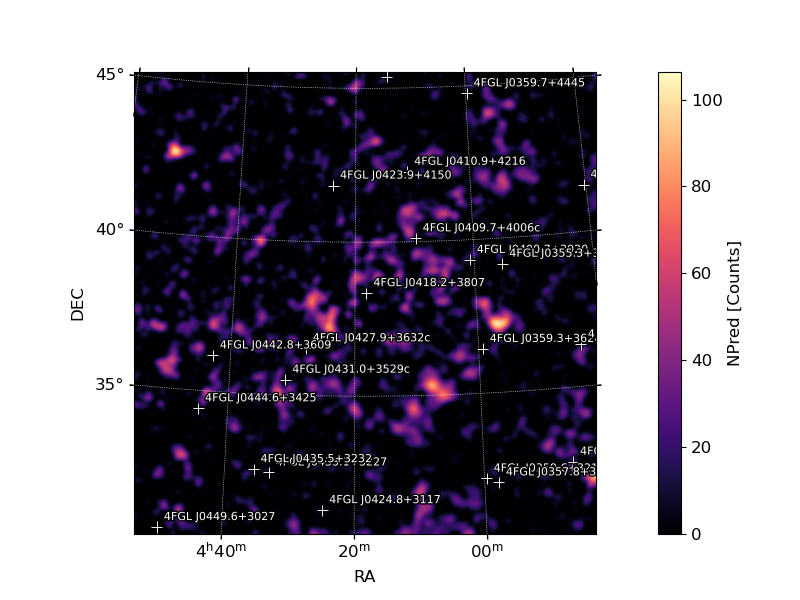

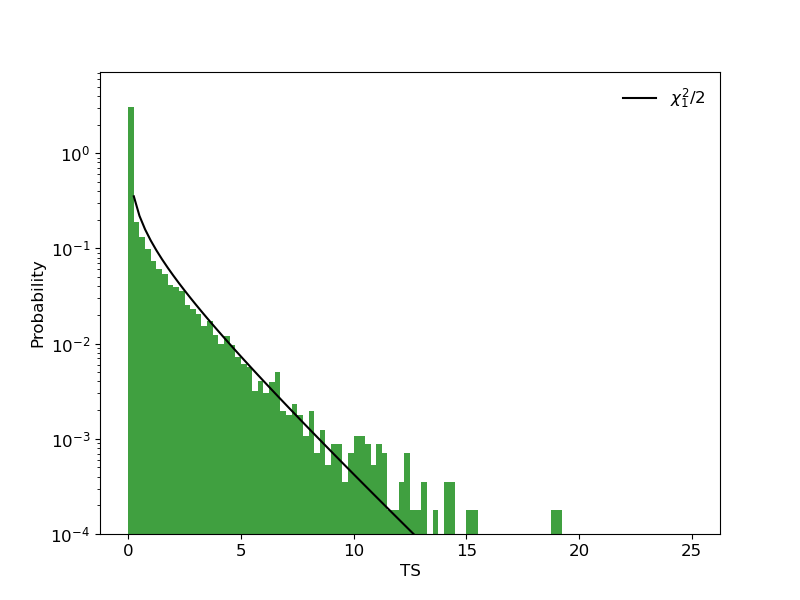

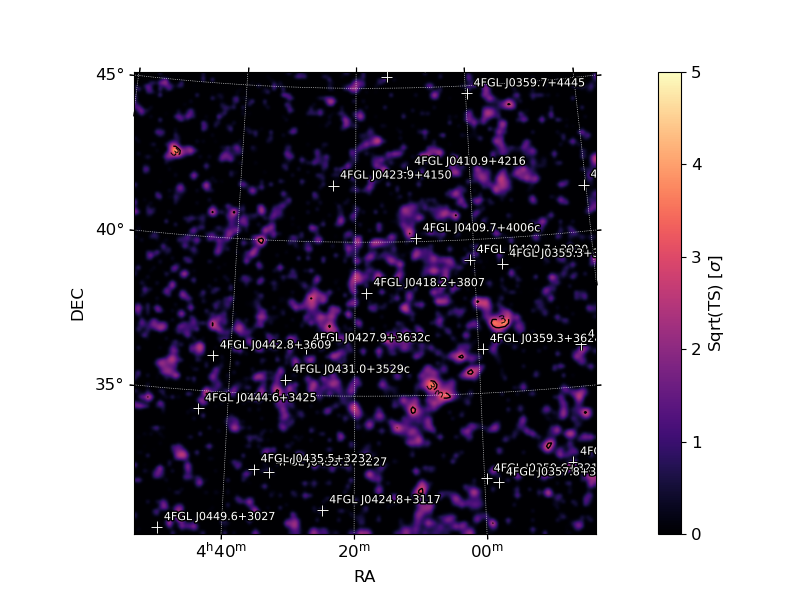

In [27]:
pngs = glob(os.path.join(work_dir,'*tsmap*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

### Residual map

In [28]:
model = {'Index' : 2.0, 'SpatialModel' : 'PointSource'}
resid = gta.residmap(make_plots=True,write_fits=True,write_npy=True)

2026-11-05 16:29:45 INFO    GTAnalysis.residmap(): Generating residual maps
2026-11-05 16:29:45 INFO    GTAnalysis.add_source(): Adding source residmap_testsource
2026-11-05 16:29:46 INFO    GTAnalysis.delete_source(): Deleting source residmap_testsource
2026-11-05 16:29:49 INFO    GTAnalysis.residmap(): Finished residual maps
2026-11-05 16:29:49 WARNING GTAnalysis.residmap(): Saving maps in .npy files is disabled b/c of incompatibilities in python3, remove the maps from the /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/pointsource_powerlaw_2.00_residmap.npy
2026-11-05 16:29:49 INFO    GTAnalysis.residmap(): Execution time: 4.32 s


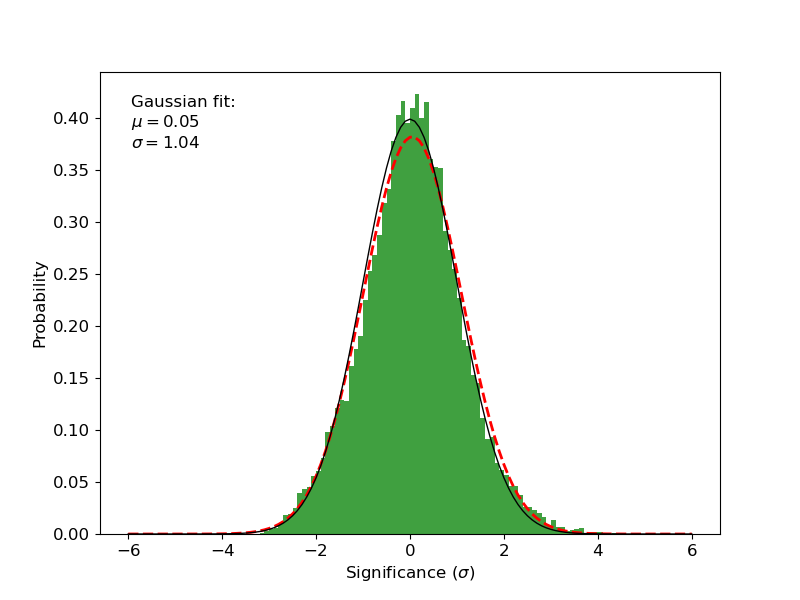

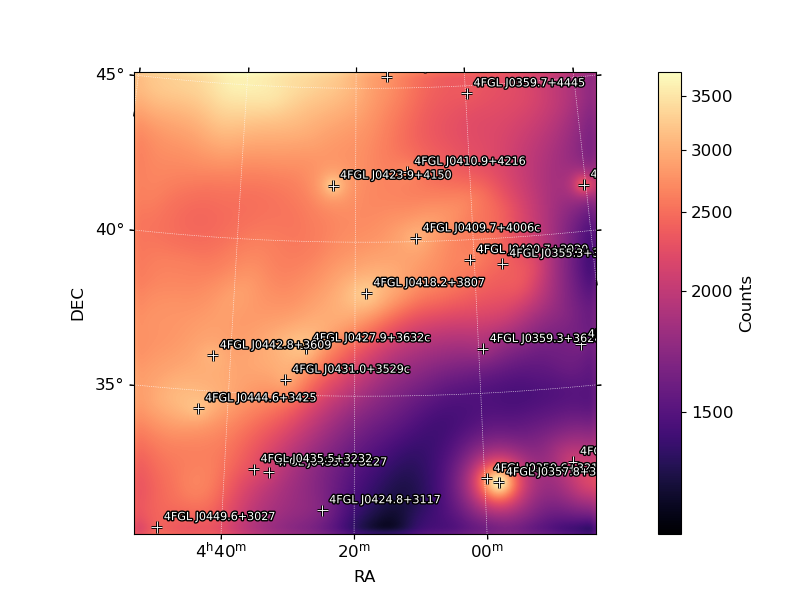

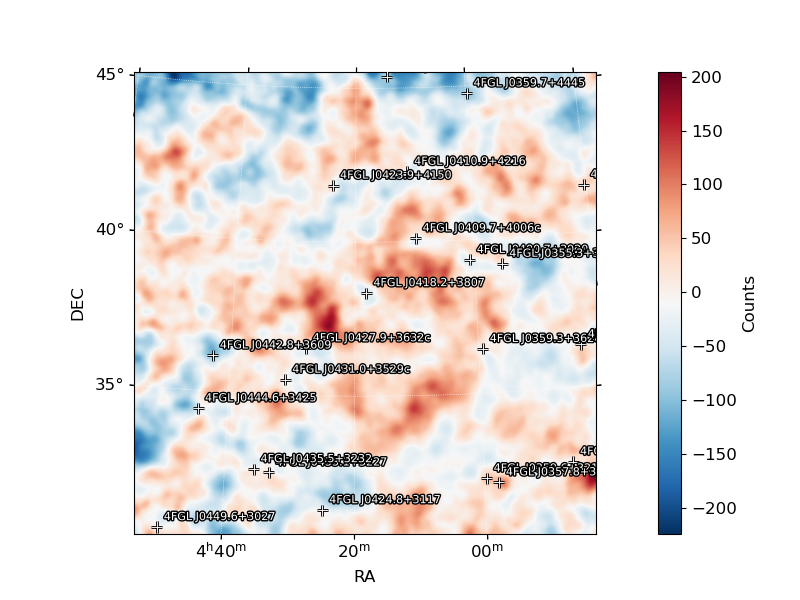

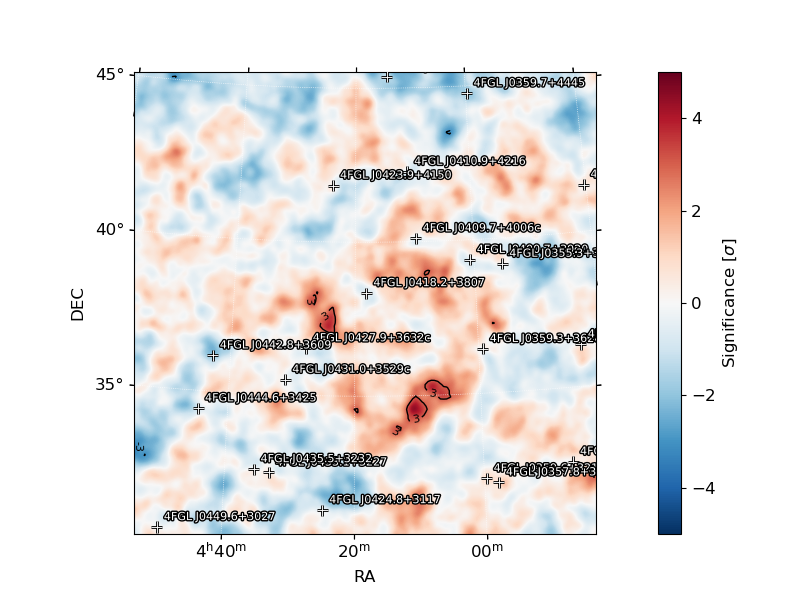

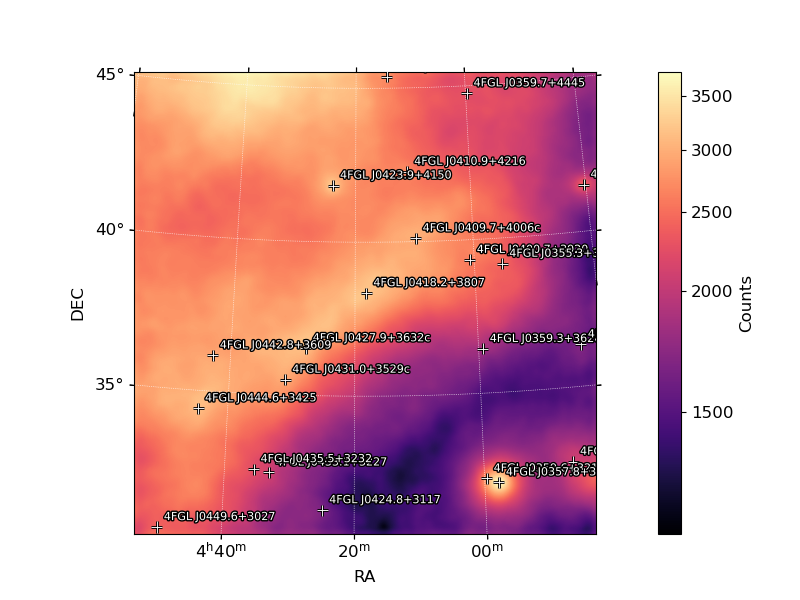

In [29]:
pngs = glob(os.path.join(work_dir,'*residmap*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

### SED analysis

To extract a bin-by-bin flux spectrum (i.e. a SED) you can call sed() method with the name of the source:

In [30]:
sedsrc = gta.sed(srcname,make_plots=True)

2026-11-05 16:29:49 INFO    GTAnalysis.sed(): Computing SED for 4FGL J0418.2+3807
2026-11-05 16:29:54 INFO    GTAnalysis._make_sed(): Fitting SED
2026-11-05 16:29:54 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0418.2+3807     : ['alpha', 'beta']
2026-11-05 16:29:54 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0427.9+3632c    : ['alpha', 'beta']
2026-11-05 16:29:54 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0409.7+4006c    : ['alpha', 'beta']
2026-11-05 16:29:55 INFO    GTAnalysis.free_source(): Fixing parameters for galdiff               : ['Index']
2026-11-05 16:29:57 INFO    GTAnalysis.sed(): Finished SED
2026-11-05 16:29:59 INFO    GTAnalysis.sed(): Execution time: 9.21 s


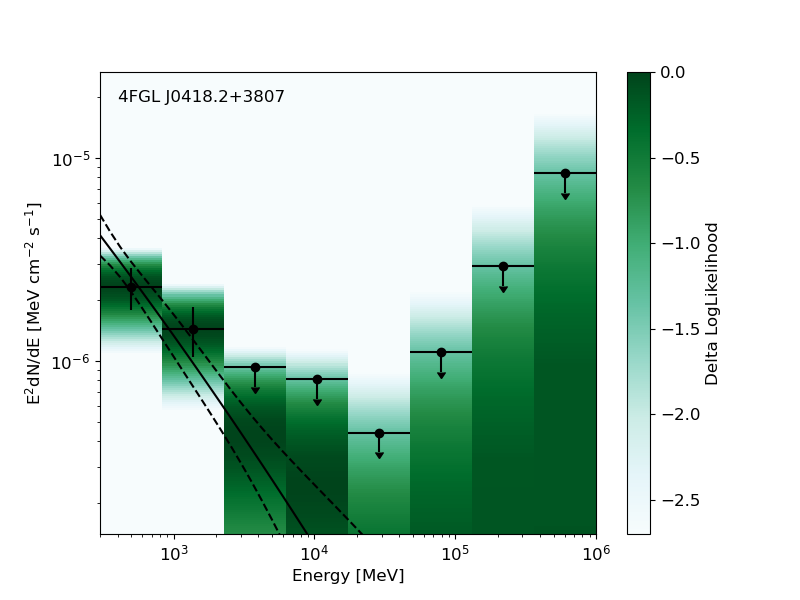

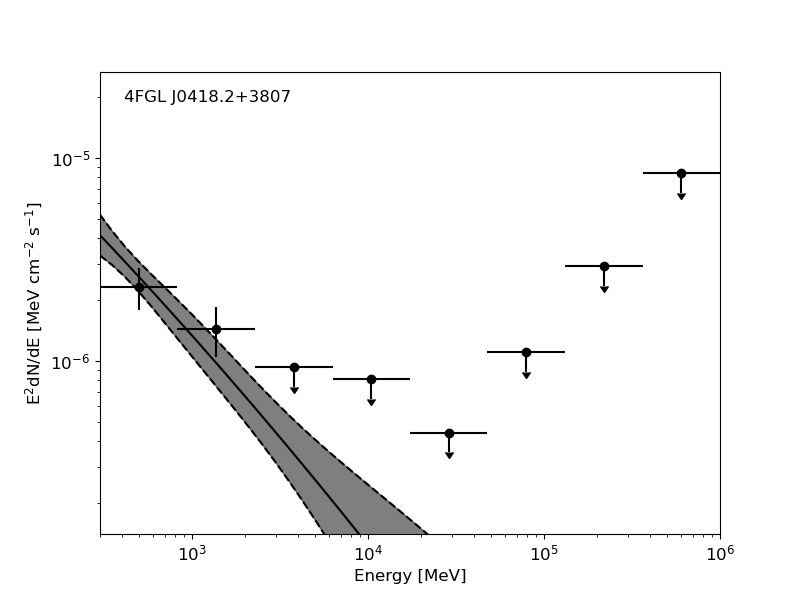

In [31]:
pngs = glob(os.path.join(work_dir,'*sed*.png'))
for png in pngs:
    my_image = Image(png)
    display(my_image)

### Light curve

In [32]:
gta.free_sources(free = False)
gta.free_source(srcname,pars='norm')


# Free all parameters of isotropic and galactic diffuse components
gta.free_source('galdiff')
gta.free_source('isodiff')

2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0418.2+3807     : ['norm', 'alpha', 'beta']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0427.9+3632c    : ['norm', 'alpha', 'beta']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0409.7+4006c    : ['norm', 'alpha', 'beta']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0431.0+3529c    : ['norm']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0400.7+3920     : ['Prefactor']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0423.9+4150     : ['norm']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0359.3+3626     : ['norm']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters for 4FGL J0410.9+4216     : ['norm']
2026-11-05 16:29:59 INFO    GTAnalysis.free_source(): Fixing parameters 

In [33]:
lc = gta.lightcurve(srcname, nbins=8,multithread=True,free_background=True)

2026-11-05 16:29:59 INFO    GTAnalysis.lightcurve(): Computing Lightcurve for 4FGL J0418.2+3807
2026-11-05 16:30:06 INFO    lightcurve_410227203_418111203 GTAnalysis._process_lc_bin(): Fitting time range 410227203 418111203
2026-11-05 16:30:06 INFO    lightcurve_418111203_425995203 GTAnalysis._process_lc_bin(): Fitting time range 418111203 425995203
2026-11-05 16:30:06 INFO    lightcurve_425995203_433879203 GTAnalysis._process_lc_bin(): Fitting time range 425995203 433879203
2026-11-05 16:30:06 INFO    lightcurve_433879203_441763204 GTAnalysis._process_lc_bin(): Fitting time range 433879203 441763203
2026-11-05 16:30:06 INFO    lightcurve_441763204_449647204 GTAnalysis._process_lc_bin(): Fitting time range 441763203 449647203
2026-11-05 16:30:06 INFO    lightcurve_449647204_457531204 GTAnalysis._process_lc_bin(): Fitting time range 449647203 457531203
2026-11-05 16:30:06 INFO    lightcurve_465415204_473299204 GTAnalysis._process_lc_bin(): Fitting time range 465415203 473299204
2026-11-

Joint fit  ['4FGL J0357.8+3204']


2026-11-05 16:30:13 INFO    lightcurve_418111203_425995203 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_418111203_425995203/base_00.xml...
2026-11-05 16:30:13 INFO    lightcurve_457531204_465415204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_457531204_465415204/base_00.xml...
2026-11-05 16:30:13 INFO    lightcurve_465415204_473299204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_465415204_473299204/base_00.xml...


Joint fit Joint fit   ['4FGL J0357.8+3204']['4FGL J0357.8+3204']

Joint fit  ['4FGL J0357.8+3204']


2026-11-05 16:30:14 INFO    lightcurve_441763204_449647204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_441763204_449647204/base_00.xml...
2026-11-05 16:30:14 INFO    lightcurve_449647204_457531204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_449647204_457531204/base_00.xml...


Joint fit  ['4FGL J0357.8+3204']
Joint fit  ['4FGL J0357.8+3204']


... (5 outputs left out)

Fitting shape 4FGL J0357.8+3204 TS:    358.582
Fitting shape 4FGL J0357.8+3204 TS:    252.968
Fitting shape 4FGL J0357.8+3204 TS:    329.316
Fitting shape 4FGL J0357.8+3204 TS:    345.641
Fitting shape 4FGL J0357.8+3204 TS:    286.835
Fitting shape 4FGL J0340.3+4130 TS:     74.956
Fitting shape 4FGL J0357.8+3204 TS:    370.381
Fitting shape 4FGL J0423.9+4150 TS:     46.443
Fitting shape 4FGL J0340.3+4130 TS:     61.641
Fitting shape 4FGL J0340.3+4130 TS:     54.523
Fitting shape 4FGL J0423.9+4150 TS:     83.997
Fitting shape 4FGL J0423.9+4150 TS:     39.129
Fitting shape 4FGL J0423.9+4150 TS:     92.424
Fitting shape 4FGL J0340.3+4130 TS:     37.670


/home/bronzini/.conda/envs/my_fermipy_v1.4.1/lib/python3.9/site-packages/fermipy/utils.py:793: UserWarning: 
The maximal number of iterations maxit (set to 20 by the program)
allowed for finding a smoothing spline with fp=s has been reached: s
too small.
There is an approximation returned but the corresponding weighted sum
of squared residuals does not satisfy the condition abs(fp-s)/s < tol.
  spline = UnivariateSpline(x, y, k=2,


Fitting shape 4FGL J0357.8+3204 TS:    335.248
Fitting shape 4FGL J0423.9+4150 TS:     34.660
Fitting shape 4FGL J0423.9+4150 TS:     54.023
Fitting shape 4FGL J0340.3+4130 TS:     76.669
Fitting shape 4FGL J0410.9+4216 TS:     22.131
Fitting shape 4FGL J0340.3+4130 TS:     69.502
Fitting shape 4FGL J0357.8+3204 TS:    324.604
Fitting shape 4FGL J0340.3+4130 TS:     95.833
Fitting shape 4FGL J0410.9+4216 TS:     26.574
Fitting shape 4FGL J0423.9+4150 TS:     75.549
Fitting shape 4FGL J0423.9+4150 TS:     57.124
Fitting shape 4FGL J0340.3+4130 TS:     43.160
Fitting shape 4FGL J0444.6+3425 TS:     19.419


2026-11-05 16:30:22 INFO    lightcurve_418111203_425995203 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_418111203_425995203/fit_model_final_00.xml...
2026-11-05 16:30:23 INFO    lightcurve_465415204_473299204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_465415204_473299204/fit_model_final_00.xml...
2026-11-05 16:30:23 INFO    lightcurve_433879203_441763204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/lightcurve_433879203_441763204/fit_model_final_00.xml...
2026-11-05 16:30:23 INFO    lightcurve_449647204_457531204 GTBinnedAnalysis.write_xml(): Writing /blasco/users/bronzini/labx/3c111/3c111_fermi/3c111_fermi_140101_160101/3c111_fermi_140101_160101_300MeV1TeV/light

Inspect parameters in lc. Here, we show only points. However, some bins are clearly consistent with 0. Plot upper limits at 95\% level of confidence instead of datapoints if the source is detected at less than 3 sigmas. Check also if the source is variable: compare the TS variability with a chi squared test with the same number of degrees of freedom.

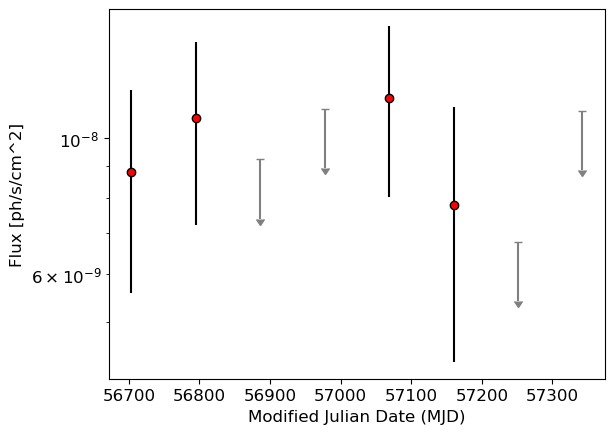

In [35]:
mask_ul = (lc['ts']>=4)
plt.errorbar((lc['tmin_mjd'][mask_ul]+lc['tmax_mjd'][mask_ul])/2,lc['flux'][mask_ul],lc['flux_err'][mask_ul],linestyle='none',marker='o',mfc='r',color='k')
plt.errorbar((lc['tmin_mjd'][~mask_ul]+lc['tmax_mjd'][~mask_ul])/2,lc['flux_ul95'][~mask_ul],0.2*lc['flux_ul95'][~mask_ul],uplims=True,marker='_',linestyle='none',c='grey')
plt.ylabel('Flux [ph/s/cm^2]')
plt.xlabel('Modified Julian Date (MJD)')

plt.yscale('log')
plt.show()